# 08 · Full fine-tuning, forgetting, and fine-tuning with covariates

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/epjover/chronos2-in-practice/blob/main/notebooks/08_finetune_full.ipynb)

Companion notebook for *Chronos-2 in Practice (4/7)*. **Needs a GPU**, and
[`07_finetune_lora`](07_finetune_lora.ipynb) must have run first: this notebook reuses its
adapters and its results.

**What you will learn**

- `finetune_mode="full"`: every weight trained, at the library's default learning rate for
  this mode, ten times lower than LoRA's.
- The comparison table the decision needs, with three seeds behind every row: error, training
  time, peak VRAM, artifact size and inference latency, side by side.
- Forgetting, measured rather than assumed: every fine-tuned model evaluated on a domain the
  fine-tune never saw.
- Fine-tuning *with covariates*, on the task where zero-shot leaves more room: the price with
  the operator's day-ahead forecasts, the budget again chosen on validation.

Runtime: ~1 h on an RTX 3070 (FAST_MODE: ~6 min).

In [1]:
# On Google Colab, clone the companion repo and install it (Colab's own PyTorch is kept).
# Locally, `uv sync` already installed everything and this cell does nothing.
import sys

if "google.colab" in sys.modules:
    !git clone --depth 1 https://github.com/epjover/chronos2-in-practice.git
    %cd chronos2-in-practice
    %pip install -q .
    import importlib

    importlib.invalidate_caches()

In [2]:
import time

import pandas as pd
import torch
from huggingface_hub.utils import logging as hub_logging
from IPython.display import Image, display
from transformers.utils import logging as transformers_logging

from c2p.config import SEED, get_device, get_paths, is_fast_mode, set_seed
from c2p.data import spain_energy_frame, spain_weather_frame, validate_and_prepare
from c2p.eval import (
    MODEL_COL,
    BacktestConfig,
    backtest,
    evaluate,
    skill_table,
    summarize_runs,
)
from c2p.experiments import (
    DAY_AHEAD_BLOCK,
    FREQ,
    LOAD,
    PRICE,
    TRAIN_END,
    TSO_COVARIATES,
    VALIDATION_END,
    day_ahead_config,
    rotating_sample_config,
    validation_config,
)
from c2p.finetune import (
    finetune,
    load_finetuned,
    lora_config,
    temporal_split,
    to_fit_inputs,
    to_univariate_series,
    window_series,
)
from c2p.models import Chronos2Forecaster, load_chronos2
from c2p.plots.evaluation import plot_skill_scores
from c2p.plotting import save_figure, set_style
from c2p.results import load_results, run_metadata, save_results
from c2p.schema import ID_COL, TIMESTAMP_COL

FAST_MODE = is_fast_mode(default=False)
PATHS = get_paths(fast_mode=FAST_MODE)
set_seed()
DEVICE = get_device()
set_style()
hub_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()

if DEVICE != "cuda":
    print("WARNING: no GPU visible; full fine-tuning on a CPU is not practical. Use Colab.")
for key, value in run_metadata(device=DEVICE, fast_mode=FAST_MODE).items():
    print(f"{key:>20}: {value}")

              python: 3.11.17
              device: cuda
           fast_mode: False
                seed: 42
          run_at_utc: 2026-11-26 15:29
                 cpu: 12th Gen Intel(R) Core(TM) i9-12900K
     cores_available: 8
       torch_threads: 8
                 gpu: NVIDIA GeForce RTX 3070 (8 GiB)
 chronos-forecasting: 2.3.2
               torch: 2.14.1
              pandas: 3.1.0
               numpy: 2.4.6
                 fev: 0.10.0
       statsforecast: 2.0.1


## 1. The same split, the same data

Everything about the data is identical to notebook `07`, which is what makes the runs
comparable: same 26 univariate Spanish series, same train/validation/test periods, same horizon
and context, same three seeds.

In [3]:
HORIZON = 24
CONTEXT = 2048
STEPS = 50 if FAST_MODE else 1000
EVAL_STEPS = 10 if FAST_MODE else 100
BATCH = 32
SEEDS = (SEED,) if FAST_MODE else (SEED, SEED + 1, SEED + 2)

raw = spain_energy_frame()
numeric = [column for column in raw.columns if column not in (ID_COL, TIMESTAMP_COL)]
frame, report = validate_and_prepare(raw[[ID_COL, TIMESTAMP_COL, *numeric]], freq=FREQ, target=LOAD)
univariate = to_univariate_series(frame, numeric)
split = temporal_split(
    univariate, val_start=TRAIN_END + pd.Timedelta(hours=1), test_start="2018-01-01"
)
train_inputs = to_fit_inputs(split.train, freq=FREQ, prediction_length=HORIZON)
val_frame = window_series(
    split.train, split.val, prediction_length=HORIZON, freq=FREQ, step=168, max_context=CONTEXT
)
val_inputs = to_fit_inputs(val_frame, freq=FREQ, prediction_length=HORIZON)

LOAD_FRAME = frame[[ID_COL, TIMESTAMP_COL, LOAD]]
LOAD_TEST = (LOAD_FRAME, day_ahead_config(FAST_MODE, max_context=CONTEXT))
print(
    f"{len(train_inputs)} training series, {len(val_inputs)} validation windows, "
    f"{LOAD_TEST[1].n_windows} test windows, seeds {SEEDS}"
)


def score(model: Chronos2Forecaster, on: tuple[pd.DataFrame, BacktestConfig]) -> pd.DataFrame:
    """Per-window metrics of ``model`` on a (frame, backtest configuration) pair."""
    series, config = on
    return evaluate(backtest(model, series, config), series, config)


def train(
    name: str,
    *,
    mode: str,
    seed: int,
    steps: int,
    learning_rate: float,
    inputs: tuple[list, list],
    rank: int | None = None,
) -> tuple[dict[str, object], Chronos2Forecaster]:
    """Fine-tune one model; return its cost row and the reloaded checkpoint as a forecaster."""
    fit_inputs, fit_validation = inputs
    result = finetune(
        load_chronos2(device=DEVICE),
        fit_inputs,
        val_inputs=fit_validation,
        mode=mode,
        prediction_length=HORIZON,
        num_steps=steps,
        learning_rate=learning_rate,
        batch_size=BATCH,
        context_length=CONTEXT,
        output_dir=PATHS.models / name,
        lora_config=lora_config(r=rank) if rank is not None else None,
        early_stopping_patience=3,
        eval_steps=EVAL_STEPS,
        seed=seed,
        overwrite=True,
    )
    print(
        f"{name}: {result.trainable_parameters:,} trainable "
        f"({result.trainable_parameters / result.total_parameters:.1%}), "
        f"{result.train_seconds / 60:.1f} min, peak VRAM {result.peak_vram_mb:.0f} MB, "
        f"{result.artifact_mb:.1f} MB on disk, best step {result.best_step} of {result.steps}, "
        f"validation loss {result.best_eval_loss:.4f}"
    )
    cost = {"run": name, "rank": rank, "seed": seed, "learning_rate": learning_rate}
    return cost | result.summary(), Chronos2Forecaster(result.pipeline, name=name)

26 training series, 702 validation windows, 365 test windows, seeds (42, 43, 44)


## 2. Training every weight

Two changes from LoRA, and only one of them is a hyperparameter:

- **`mode="full"`**: all 119.5M parameters get gradients, instead of about 1%.
- **A learning rate of 1e-6**, a tenth of LoRA's. This is the default of
  `Chronos2Pipeline.fit`, whose documentation recommends the higher 1e-5 only for LoRA. The
  usual reasoning is that with the pretrained weights themselves moving, a rate that suits a
  small adapter can move the model off what it learned in pretraining. This notebook does not
  try a higher rate for the full fine-tune.

The cost shows up in memory rather than in time (optimizer state for every parameter), which is why peak VRAM is the column to watch in the table below. Three seeds, as for every other row.

In [4]:
start = time.perf_counter()
full_costs, full_frames = [], []
for seed in SEEDS:
    cost, model = train(
        f"full_s{seed}",
        mode="full",
        seed=seed,
        steps=STEPS,
        learning_rate=1e-6,
        inputs=(train_inputs, val_inputs),
    )
    full_costs.append(cost)
    full_frames.append(score(model, LOAD_TEST))
    print(f"  test WQL {full_frames[-1]['WQL'].mean():.4f}")
    del model
    torch.cuda.empty_cache()
print(f"{len(SEEDS)} full fine-tunes in {(time.perf_counter() - start) / 60:.0f} min")
print("Saved", save_results(pd.DataFrame(full_costs), "08_full_costs", PATHS).name)
print(
    "Saved", save_results(pd.concat(full_frames, ignore_index=True), "08_full_metrics", PATHS).name
)

full_s42: 119,477,664 trainable (100.0%), 6.0 min, peak VRAM 5497 MB, 455.8 MB on disk, best step 1000 of 1000, validation loss 2.9767
  test WQL 0.0373
full_s43: 119,477,664 trainable (100.0%), 4.9 min, peak VRAM 5499 MB, 455.8 MB on disk, best step 1000 of 1000, validation loss 2.9928
  test WQL 0.0373
full_s44: 119,477,664 trainable (100.0%), 5.1 min, peak VRAM 5499 MB, 455.8 MB on disk, best step 1000 of 1000, validation loss 2.9858
  test WQL 0.0372
3 full fine-tunes in 17 min
Saved 08_full_costs.csv
Saved 08_full_metrics.csv


## 3. Four models, one table

The LoRA runs of notebook `07` are read from its results: rank 8 at the library's defaults,
and rank 8 at the budget chosen on validation, three seeds each. Every row is the average of
its three seeds window by window; `run_skill_min` and `run_skill_max` say how far single runs
sit from it. `mean_change` is the change in mean WQL, which the bad days dominate; `skill` is
the geometric one, which every day weighs on equally. When they differ, the gain is not spread
evenly over the days.

In [5]:
lora_metrics = load_results("07_lora_metrics", PATHS)
tuned_metrics = load_results("07_tuned_metrics", PATHS)
full_metrics = load_results("08_full_metrics", PATHS)
tuned_budget = (
    load_results("07_tuned_summary", PATHS).set_index("model").loc["lora_tuned", "budget"]
)

RUNS = {
    "lora_r8": [f"lora_r8_s{seed}" for seed in SEEDS],
    "lora_tuned": load_results("07_tuned_costs", PATHS)["run"].tolist(),
    "full": [f"full_s{seed}" for seed in SEEDS],
}
all_runs = pd.concat([lora_metrics, tuned_metrics, full_metrics], ignore_index=True)
all_runs = all_runs.drop_duplicates([MODEL_COL, "window"])
comparison, compare = summarize_runs(
    all_runs, RUNS, baseline="zero-shot", block_length=DAY_AHEAD_BLOCK
)
print("Saved", save_results(compare, "08_comparison_metrics", PATHS).name)

costs = pd.concat(
    [
        load_results("07_lora_costs", PATHS),
        load_results("07_tuned_costs", PATHS),
        load_results("08_full_costs", PATHS),
    ],
    ignore_index=True,
).drop_duplicates("run")
for column in ("train_seconds", "peak_vram_mb", "artifact_mb", "best_eval_loss", "num_steps"):
    comparison[column] = [
        costs.loc[costs["run"].isin(runs), column].mean() for runs in RUNS.values()
    ]
comparison["latency_ms"] = [
    1000 * all_runs.loc[all_runs[MODEL_COL].isin(runs), "seconds"].median()
    for runs in RUNS.values()
]
comparison["budget"] = ["library defaults", tuned_budget, "1e-6, all weights"]
print("Saved", save_results(comparison, "08_comparison_summary", PATHS).name)
compare_skill = skill_table(
    compare, baseline="zero-shot", metric="WQL", block_length=DAY_AHEAD_BLOCK
)
print("Saved", save_results(compare_skill, "08_comparison_skill", PATHS).name)
comparison.round(4)

Saved 08_comparison_metrics.csv
Saved 08_comparison_summary.csv
Saved 08_comparison_skill.csv


,model,n_runs,WQL,mean_change,skill,ci_low,ci_high,win_rate,run_skill_min,run_skill_max,coverage_80,coverage_98,train_seconds,peak_vram_mb,artifact_mb,best_eval_loss,num_steps,latency_ms,budget
0,lora_r8,3,0.0374,-0.0346,0.0265,0.0045,0.0478,0.5589,0.0229,0.0298,0.7217,0.9449,311.1148,3767.2681,4.6358,3.1006,1000.0,34.5607,library defaults
1,lora_tuned,3,0.0337,-0.1293,0.0804,0.0233,0.1328,0.5918,0.0833,0.0980,0.7016,0.9554,618.5086,3767.2681,4.6358,2.6836,4000.0,34.9737,"4,000 steps, lr 1e-4"
2,full,3,0.0373,-0.0385,0.0199,-0.0204,0.0576,0.5397,0.0168,0.0272,0.6969,0.9357,320.0309,5497.9393,455.7910,2.9851,1000.0,34.7066,"1e-6, all weights"


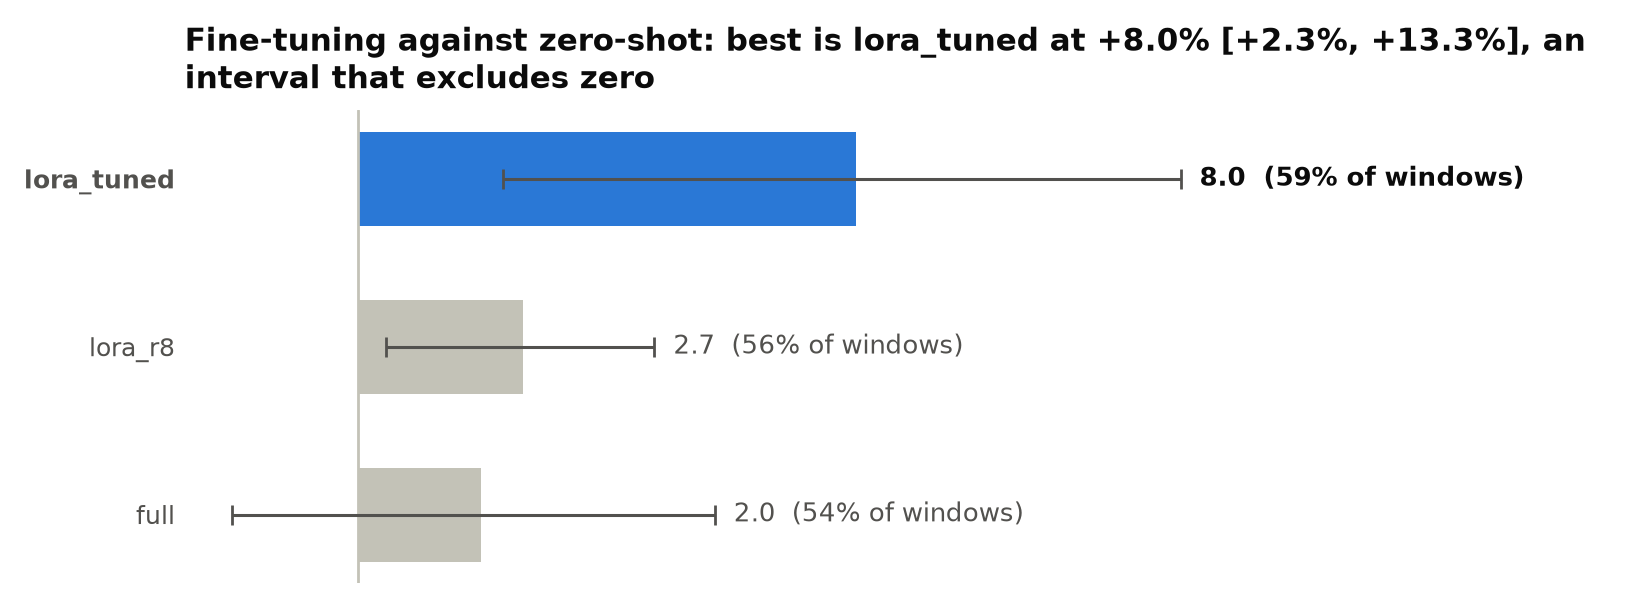

In [6]:
compare_skill = load_results("08_comparison_skill", PATHS)
best = compare_skill[compare_skill["model"] != "zero-shot"].iloc[0]
# A point estimate above zero is not a win: say whether the interval clears zero.
verdict = "excludes" if best["ci_low"] > 0 or best["ci_high"] < 0 else "includes"
title = (
    f"Fine-tuning against zero-shot: best is {best['model']} at {best['skill']:+.1%} "
    f"[{best['ci_low']:+.1%}, {best['ci_high']:+.1%}], an interval that {verdict} zero"
)
ax = plot_skill_scores(
    compare_skill,
    highlight=str(best["model"]),
    title=title,
    xlabel="WQL improvement over the zero-shot model (%), three seeds averaged",
)
(figure_path,) = save_figure(ax.figure, "08_comparison", PATHS.figures)
display(Image(filename=figure_path, width=800))

The table leaves two questions open, and the same per-window metrics answer both.

**Is one fine-tune better than another?** The intervals above are each against the zero-shot
model, and two intervals that overlap do not settle a comparison. The paired skill does: the
same windows, one model against the other.

**On which days is the gain?** The windows are split into thirds by how hard the day is for the
seasonal naive, a model that is not part of the comparison. Splitting by the zero-shot model's
own error would be circular: the days it did worst on are days any other model looks better on.
Within a third the windows are not consecutive, so these intervals resample single windows.

In [7]:
from c2p.baselines import SeasonalNaive

compare = load_results("08_comparison_metrics", PATHS)
paired = pd.concat(
    [
        skill_table(
            compare[compare[MODEL_COL].isin([model, reference])],
            baseline=reference,
            metric="WQL",
            block_length=DAY_AHEAD_BLOCK,
        ).query(f"{MODEL_COL} == @model")
        for model, reference in (("lora_tuned", "lora_r8"), ("full", "lora_r8"))
    ],
    ignore_index=True,
)
print("Saved", save_results(paired, "08_paired_skill", PATHS).name)

naive = score(SeasonalNaive(season_length=24), LOAD_TEST).set_index("window")["WQL"]
THIRDS = ["easiest third", "middle third", "hardest third"]
difficulty = pd.qcut(naive, 3, labels=THIRDS)
rows = []
for third in THIRDS:
    windows = difficulty.index[difficulty == third]
    subset = compare[compare["window"].isin(windows)]
    table = skill_table(subset, baseline="zero-shot", metric="WQL")
    table = table[table[MODEL_COL] != "zero-shot"]
    zero_wql = subset.loc[subset[MODEL_COL] == "zero-shot", "WQL"].mean()
    rows.append(
        table.assign(days=third, seasonal_naive_wql=naive[windows].mean(), zero_shot_wql=zero_wql)
    )
by_difficulty = pd.concat(rows, ignore_index=True)
print("Saved", save_results(by_difficulty, "08_gain_by_difficulty", PATHS).name)

columns = ["skill", "ci_low", "ci_high", "win_rate", "n_units"]
display(paired.set_index([MODEL_COL, "baseline"])[columns].round(4))
by_difficulty.set_index([MODEL_COL, "days"])[[*columns, "zero_shot_wql"]].round(4)

Saved 08_paired_skill.csv
Saved 08_gain_by_difficulty.csv


,,skill,ci_low,ci_high,win_rate,n_units
model,baseline,,,,,
lora_tuned,lora_r8,0.0553,0.0064,0.1001,0.5753,365
full,lora_r8,-0.0068,-0.0300,0.0155,0.5178,365


,,skill,ci_low,ci_high,win_rate,n_units,zero_shot_wql
model,days,,,,,,
lora_r8,easiest third,0.0012,-0.0280,0.0278,0.5492,122,0.0125
lora_tuned,easiest third,-0.0185,-0.0977,0.0479,0.5246,122,0.0125
full,easiest third,-0.0290,-0.0867,0.0217,0.5164,122,0.0125
lora_r8,middle third,0.0201,-0.0219,0.0631,0.5455,121,0.0409
lora_tuned,middle third,0.0156,-0.0839,0.1025,0.5537,121,0.0409
full,middle third,-0.0128,-0.1006,0.0646,0.4959,121,0.0409
lora_tuned,hardest third,0.2239,0.1540,0.2913,0.6967,122,0.0629
full,hardest third,0.0963,0.0357,0.1569,0.6066,122,0.0629
lora_r8,hardest third,0.0573,0.0237,0.0929,0.5820,122,0.0629


## 4. What did it forget?

A fine-tune trades generality for fit. The Spanish electricity table is all these models were
shown, so the question is what happened to everything else: the dataset ships a convenient
out-of-domain test, hourly temperature for five Spanish cities, a different unit, a different
scale and a different shape, never part of the training data.

A model that has specialised can be worse here. That would be the cost of specialising, and it
only matters if you plan to serve one model for several domains: this is the decision this
measurement informs. Every run is reloaded from disk and scored on 73 windows across 2018, one
every five days, so every weekday is forecast.

In [8]:
weather, weather_report = validate_and_prepare(
    spain_weather_frame(),
    freq=FREQ,
    target="temp_c",
    duplicates="mean",
    categorical=["weather_main"],
)
weather = weather[[ID_COL, TIMESTAMP_COL, "temp_c"]]
OOD = (weather, rotating_sample_config(FAST_MODE, target="temp_c", max_context=CONTEXT))

zero_shot = Chronos2Forecaster(load_chronos2(device=DEVICE), name="zero-shot")
frames = [score(zero_shot, OOD)]
del zero_shot
for runs in RUNS.values():
    for run in runs:
        pipeline = load_finetuned(PATHS.models / run / "finetuned-ckpt", device=DEVICE)
        frames.append(score(Chronos2Forecaster(pipeline, name=run), OOD))
        print(f"  {run:<28} WQL {frames[-1]['WQL'].mean():.4f} on temperature")
        del pipeline
        torch.cuda.empty_cache()
forgetting_runs = pd.concat(frames, ignore_index=True)
print("Saved", save_results(forgetting_runs, "08_forgetting_run_metrics", PATHS).name)

forgetting_summary, forgetting = summarize_runs(
    load_results("08_forgetting_run_metrics", PATHS), RUNS, baseline="zero-shot"
)
print("Saved", save_results(forgetting, "08_forgetting_metrics", PATHS).name)
print("Saved", save_results(forgetting_summary, "08_forgetting_summary", PATHS).name)
forgetting_skill = skill_table(forgetting, baseline="zero-shot", metric="WQL")
print("Saved", save_results(forgetting_skill, "08_forgetting_skill", PATHS).name)
forgetting_summary.round(4)

  lora_r8_s42                  WQL 0.0880 on temperature
  lora_r8_s43                  WQL 0.0879 on temperature
  lora_r8_s44                  WQL 0.0880 on temperature
  lora_budget_4000_0.0001      WQL 0.0935 on temperature
  lora_tuned_s43               WQL 0.0907 on temperature
  lora_tuned_s44               WQL 0.0915 on temperature
  full_s42                     WQL 0.0884 on temperature
  full_s43                     WQL 0.0883 on temperature
  full_s44                     WQL 0.0883 on temperature
Saved 08_forgetting_run_metrics.csv
Saved 08_forgetting_metrics.csv
Saved 08_forgetting_summary.csv
Saved 08_forgetting_skill.csv


,model,n_runs,WQL,mean_change,skill,ci_low,ci_high,win_rate,run_skill_min,run_skill_max,coverage_80,coverage_98
0,lora_r8,3,0.0880,-0.0081,0.0102,0.0033,0.0177,0.6712,0.0097,0.0113,0.7908,0.9685
1,lora_tuned,3,0.0919,0.0361,-0.0357,-0.0589,-0.0140,0.4384,-0.0544,-0.0210,0.8014,0.9722
2,full,3,0.0883,-0.0043,0.0073,-0.0049,0.0196,0.6301,0.0061,0.0091,0.8065,0.9734


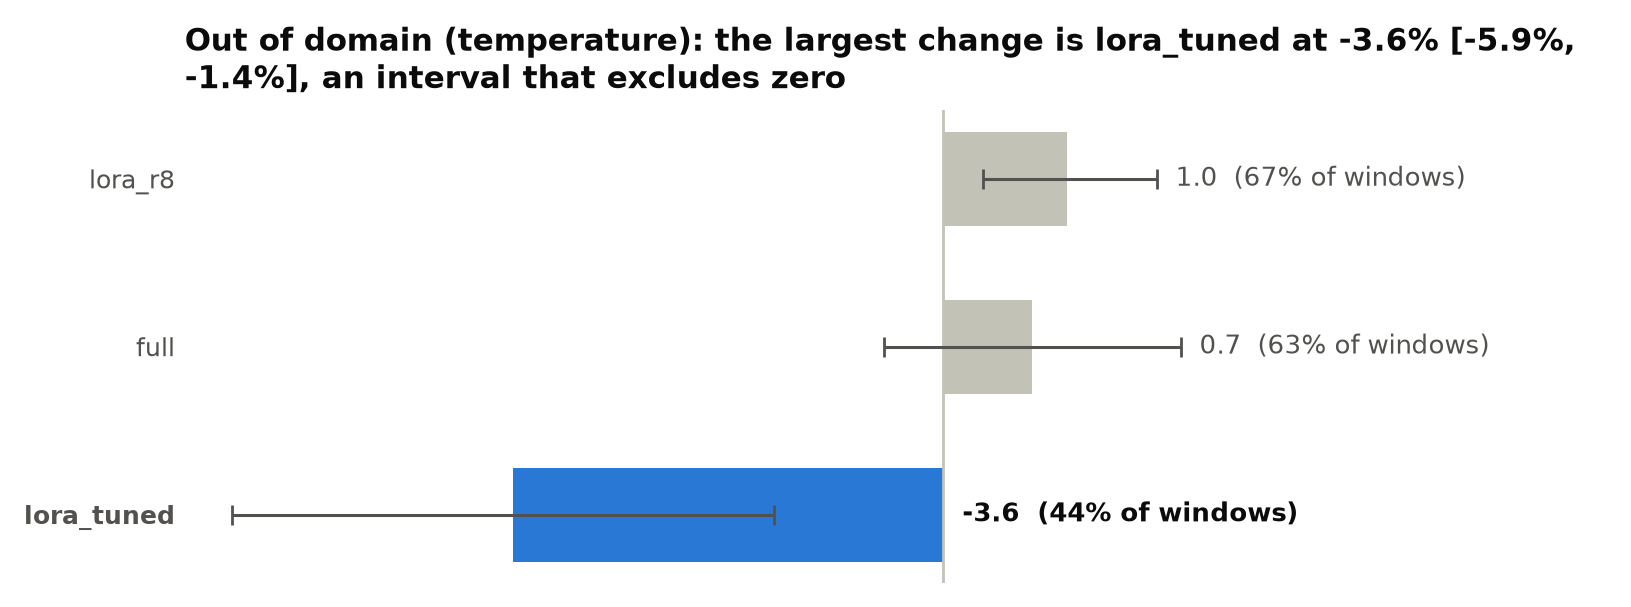

In [9]:
forgetting_skill = load_results("08_forgetting_skill", PATHS)
worst = forgetting_skill.iloc[-1]
verdict = "excludes" if worst["ci_low"] > 0 or worst["ci_high"] < 0 else "includes"
title = (
    f"Out of domain (temperature): the largest change is {worst['model']} at "
    f"{worst['skill']:+.1%} [{worst['ci_low']:+.1%}, {worst['ci_high']:+.1%}], "
    f"an interval that {verdict} zero"
)
ax = plot_skill_scores(
    forgetting_skill,
    highlight=str(worst["model"]),
    title=title,
    xlabel="WQL change on an unseen domain vs the zero-shot model (%), three seeds averaged",
)
(figure_path,) = save_figure(ax.figure, "08_forgetting", PATHS.figures)
display(Image(filename=figure_path, width=800))

## 5. Fine-tuning with covariates, where there is room

Day-ahead national load is a series on which zero-shot is already close to what the history
allows, so it is a hard place to show what fine-tuning can add. The price of notebook `05` is
the other case: covariates matter, the zero-shot error is larger, and the model has to use
three covariates it was never trained on real examples of.

`Chronos2Pipeline.fit` takes the same structure as prediction: a target, its past covariates
and the covariates whose future is known. `to_fit_inputs(..., known_covariates=...)` builds it,
and during training the model sees those columns over each sampled horizon, as it will in
`future_df`. The split, the horizon and the context are the same as above; the training data is
one series (the price) with three known-future covariates (the operator's day-ahead forecasts
of load, solar and wind), not the 26 univariate series.

The reference is the zero-shot model **with the same covariates**, so what is measured is the
fine-tuning and nothing else. Two budgets (the library's default learning rate and ten times
it), chosen on the validation backtest of the price, then three seeds on the test year.

In [10]:
KNOWN = tuple(TSO_COVARIATES)
price, _ = validate_and_prepare(
    raw[[ID_COL, TIMESTAMP_COL, PRICE, *KNOWN]], freq=FREQ, target=PRICE
)
price_split = temporal_split(
    price, val_start=TRAIN_END + pd.Timedelta(hours=1), test_start="2018-01-01"
)
covariates = {"target": PRICE, "known_covariates": KNOWN}
price_train = to_fit_inputs(price_split.train, freq=FREQ, prediction_length=HORIZON, **covariates)
price_val_frame = window_series(
    price_split.train,
    price_split.val,
    prediction_length=HORIZON,
    freq=FREQ,
    step=24,
    max_context=CONTEXT,
)
price_val = to_fit_inputs(price_val_frame, freq=FREQ, prediction_length=HORIZON, **covariates)
print(
    f"{len(price_train)} training series with {len(KNOWN)} known covariates, "
    f"{len(price_val)} validation windows"
)

price_configs = {"target": PRICE, "known_covariates": KNOWN, "max_context": CONTEXT}
PRICE_TEST = (price, day_ahead_config(FAST_MODE, **price_configs))
PRICE_VALIDATION = (
    price[price[TIMESTAMP_COL] <= VALIDATION_END],
    validation_config(FAST_MODE, **price_configs),
)
zero_shot = Chronos2Forecaster(load_chronos2(device=DEVICE), name="zero-shot")
price_zero = {
    "test": score(zero_shot, PRICE_TEST),
    "validation": score(zero_shot, PRICE_VALIDATION),
}
del zero_shot
for name, metrics in price_zero.items():
    print(
        f"zero-shot with covariates on the {name} windows: WQL {metrics['WQL'].mean():.4f}, "
        f"80% coverage {metrics['coverage_80'].mean():.1%}"
    )

1 training series with 3 known covariates, 184 validation windows
zero-shot with covariates on the test windows: WQL 0.0440, 80% coverage 77.9%
zero-shot with covariates on the validation windows: WQL 0.0400, 80% coverage 75.6%


In [11]:
PRICE_CANDIDATES = {"lr 1e-5": 1e-5, "lr 1e-4": 1e-4}
start = time.perf_counter()
price_costs, validation_frames, test_frames = [], [price_zero["validation"]], [price_zero["test"]]
for label, learning_rate in PRICE_CANDIDATES.items():
    cost, model = train(
        f"price_lora_{learning_rate:g}_s{SEED}",
        mode="lora",
        rank=8,
        seed=SEED,
        steps=STEPS,
        learning_rate=learning_rate,
        inputs=(price_train, price_val),
    )
    price_costs.append(cost | {"candidate": label})
    validation_frames.append(score(model, PRICE_VALIDATION).assign(candidate=label))
    test_frames.append(score(model, PRICE_TEST))
    del model
    torch.cuda.empty_cache()

validation = pd.concat(validation_frames, ignore_index=True)
candidate_runs = {cost["candidate"]: [cost["run"]] for cost in price_costs}
price_validation, _ = summarize_runs(
    validation.drop(columns="candidate"),
    candidate_runs,
    baseline="zero-shot",
    block_length=DAY_AHEAD_BLOCK,
)
price_validation = price_validation.rename(columns={"model": "candidate"})
for column in ("learning_rate", "best_step", "num_steps", "best_eval_loss"):
    price_validation[column] = [cost[column] for cost in price_costs]
PRICE_CHOSEN = str(price_validation.sort_values("skill", ascending=False).iloc[0]["candidate"])
price_validation["chosen"] = price_validation["candidate"] == PRICE_CHOSEN
print("Saved", save_results(price_validation, "08_price_validation", PATHS).name)
print(f"Chosen on validation: {PRICE_CHOSEN}")

chosen_rate = PRICE_CANDIDATES[PRICE_CHOSEN]
for seed in SEEDS[1:]:
    cost, model = train(
        f"price_lora_{chosen_rate:g}_s{seed}",
        mode="lora",
        rank=8,
        seed=seed,
        steps=STEPS,
        learning_rate=chosen_rate,
        inputs=(price_train, price_val),
    )
    price_costs.append(cost | {"candidate": PRICE_CHOSEN})
    test_frames.append(score(model, PRICE_TEST))
    del model
    torch.cuda.empty_cache()
print(f"Price fine-tunes in {(time.perf_counter() - start) / 60:.0f} min")
print("Saved", save_results(pd.DataFrame(price_costs), "08_price_costs", PATHS).name)
print(
    "Saved", save_results(pd.concat(test_frames, ignore_index=True), "08_price_metrics", PATHS).name
)
price_validation.round(4)

price_lora_1e-05_s42: 1,206,912 trainable (1.0%), 5.1 min, peak VRAM 3767 MB, 4.6 MB on disk, best step 800 of 1000, validation loss 0.7954
price_lora_0.0001_s42: 1,206,912 trainable (1.0%), 5.2 min, peak VRAM 3767 MB, 4.6 MB on disk, best step 800 of 1000, validation loss 0.7649
Saved 08_price_validation.csv
Chosen on validation: lr 1e-4
price_lora_0.0001_s43: 1,206,912 trainable (1.0%), 5.2 min, peak VRAM 3767 MB, 4.6 MB on disk, best step 900 of 1000, validation loss 0.7638
price_lora_0.0001_s44: 1,206,912 trainable (1.0%), 5.1 min, peak VRAM 3767 MB, 4.6 MB on disk, best step 900 of 1000, validation loss 0.7653
Price fine-tunes in 23 min
Saved 08_price_costs.csv
Saved 08_price_metrics.csv


,candidate,n_runs,WQL,mean_change,skill,ci_low,ci_high,win_rate,run_skill_min,run_skill_max,coverage_80,coverage_98,learning_rate,best_step,num_steps,best_eval_loss,chosen
0,lr 1e-5,1,0.0392,-0.0218,0.0256,0.0170,0.0349,0.6902,0.0256,0.0256,0.7491,0.9656,0.0000,800,1000,0.7954,False
1,lr 1e-4,1,0.0377,-0.0576,0.0507,0.0277,0.0733,0.6033,0.0507,0.0507,0.7278,0.9604,0.0001,800,1000,0.7649,True


In [12]:
price_metrics = load_results("08_price_metrics", PATHS)
price_costs = load_results("08_price_costs", PATHS)
PRICE_RUNS = {
    f"price LoRA, {candidate}": group["run"].tolist()
    for candidate, group in price_costs.groupby("candidate", sort=False)
}
price_summary, price_compare = summarize_runs(
    price_metrics, PRICE_RUNS, baseline="zero-shot", block_length=DAY_AHEAD_BLOCK
)
chosen_label = f"price LoRA, {PRICE_CHOSEN}"
price_summary["chosen"] = price_summary["model"] == chosen_label
print("Saved", save_results(price_summary, "08_price_summary", PATHS).name)
price_summary.round(4)

Saved 08_price_summary.csv


,model,n_runs,WQL,mean_change,skill,ci_low,ci_high,win_rate,run_skill_min,run_skill_max,coverage_80,coverage_98,chosen
0,"price LoRA, lr 1e-5",1,0.0434,-0.0142,0.0231,0.0128,0.0338,0.5918,0.0231,0.0231,0.7715,0.9716,False
1,"price LoRA, lr 1e-4",3,0.0424,-0.0367,0.0490,0.0272,0.0729,0.6055,0.0484,0.0520,0.7364,0.9640,True


## 6. The decision table

In [13]:
comparison = load_results("08_comparison_summary", PATHS).set_index("model")
ood = load_results("08_forgetting_summary", PATHS).set_index("model")
price_summary = load_results("08_price_summary", PATHS)

print("Spanish load, 365 day-ahead windows of 2018, against zero-shot (three seeds averaged):")
header = (
    f"{'model':<11} {'skill':>7} {'95% interval':>16} {'single runs':>16} {'mean WQL':>9} "
    f"{'cov80':>6} {'temp.':>7} {'train':>6} {'VRAM':>7} {'disk':>8} {'latency':>8}"
)
print(header)
for model, row in comparison.iterrows():
    print(
        f"{model:<11} {row['skill']:+7.1%} [{row['ci_low']:+6.1%}, {row['ci_high']:+6.1%}] "
        f"[{row['run_skill_min']:+6.1%}, {row['run_skill_max']:+6.1%}] {row['mean_change']:+9.1%} "
        f"{row['coverage_80']:6.1%} {ood.loc[model, 'skill']:+7.1%} "
        f"{row['train_seconds'] / 60:5.1f}m {row['peak_vram_mb']:6.0f}M {row['artifact_mb']:7.1f}M "
        f"{row['latency_ms']:6.0f}ms"
    )
print("\nSpanish price with covariates, against zero-shot with the same covariates:")
for row in price_summary.itertuples():
    mark = "  <- chosen on validation, three seeds" if row.chosen else "  (one seed)"
    print(
        f"  {row.model:<20} skill {row.skill:+.1%} [{row.ci_low:+.1%}, {row.ci_high:+.1%}], "
        f"mean WQL {row.mean_change:+.1%}, 80% coverage {row.coverage_80:.1%}{mark}"
    )

Spanish load, 365 day-ahead windows of 2018, against zero-shot (three seeds averaged):
model         skill     95% interval      single runs  mean WQL  cov80   temp.  train    VRAM     disk  latency
lora_r8       +2.7% [ +0.4%,  +4.8%] [ +2.3%,  +3.0%]     -3.5%  72.2%   +1.0%   5.2m   3767M     4.6M     35ms
lora_tuned    +8.0% [ +2.3%, +13.3%] [ +8.3%,  +9.8%]    -12.9%  70.2%   -3.6%  10.3m   3767M     4.6M     35ms
full          +2.0% [ -2.0%,  +5.8%] [ +1.7%,  +2.7%]     -3.8%  69.7%   +0.7%   5.3m   5498M   455.8M     35ms

Spanish price with covariates, against zero-shot with the same covariates:
  price LoRA, lr 1e-5  skill +2.3% [+1.3%, +3.4%], mean WQL -1.4%, 80% coverage 77.1%  (one seed)
  price LoRA, lr 1e-4  skill +4.9% [+2.7%, +7.3%], mean WQL -3.7%, 80% coverage 73.6%  <- chosen on validation, three seeds


**Next:** article 5 leaves the notebooks behind and runs from scripts:
[`bench/bench_cpu_gpu.py`](../bench/bench_cpu_gpu.py) for latency and throughput on CPU and
GPU, [`deploy/`](../deploy/) for three ways to serve the model (and the command that deletes
each one) and [`scripts/cost_table.py`](../scripts/cost_table.py) for the cost per million
forecasts. Article 6 follows with [`monitoring/build_panel.py`](../monitoring/build_panel.py),
the panel that tells you when this adapter has stopped working, and the calibration of the
intervals.